# Mapping
1.  Plotting Points
    2. Static
    3. Interactive  
3.  Choropleths
4.  rasters
## Geopandas

### I think these are the packages you will need.  
uv add geopandas

uv add rioxarray

uv add folium

uv add mapclassify

### You can add in one line

uv add geopandas rioxarray folium mapclassify

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# NEW!
import geopandas as gpd
import rioxarray
import folium
import xarray as xr

## Step 1 Make a World Map
- I downloaded a shape file from Natural Earth
- https://www.naturalearthdata.com/
- You can just use the .shp file from github
- read the file into geopandas like you read a file into pandas

In [63]:
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)

#### Look at the data

In [64]:
world

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,NaN,NaN,Unrecognized,NaN,NaN,NaN,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,Admin-0 country,1,5,Republic of Serbia,SRB,0,2,Sovereign country,1,Republic of Serbia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((18.82982 45.90887, 18.82984 45.90888..."
173,Admin-0 country,1,6,Montenegro,MNE,0,2,Sovereign country,1,Montenegro,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((20.0707 42.58863, 19.80161 42.50009,..."
174,Admin-0 country,1,6,Kosovo,KOS,0,2,Disputed,1,Kosovo,...,Admin-0 country,Unrecognized,Admin-0 country,Unrecognized,Admin-0 country,Admin-0 country,Admin-0 country,Admin-0 country,Unrecognized,"POLYGON ((20.59025 41.85541, 20.52295 42.21787..."
175,Admin-0 country,1,5,Trinidad and Tobago,TTO,0,2,Sovereign country,1,Trinidad and Tobago,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-61.68 10.76, -61.105 10.89, -60.895..."


#### Look at the info

In [65]:
world.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 177 entries, 0 to 176
Columns: 169 entries, featurecla to geometry
dtypes: float64(6), geometry(1), int32(24), int64(1), object(1), str(136)
memory usage: 217.2+ KB


### Quick Plot

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

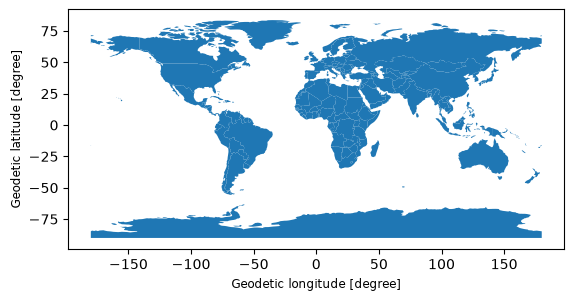

In [66]:
world.plot()

### Professional Plot

Text(0.5, 1.0, 'World Map (EPSG:4326)')

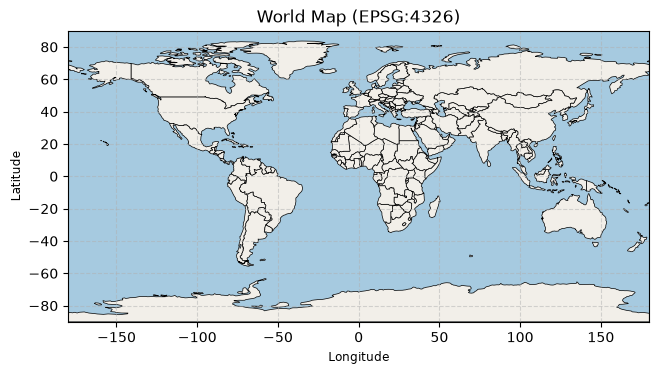

In [110]:
# readin in world data
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)


fig, ax = plt.subplots()
fig.set_size_inches(7.5, 5)

# Plot land and country borders
world.plot(ax=ax, color="#f2efe9", edgecolor="black", linewidth=0.5)

# Clamp to true global coordinates (eliminates the blue gap below Antarctica)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)

# Add ocean background and gridlines
ax.set_facecolor("#a6cae0")
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("World Map (EPSG:4326)")

### World Map with a natural background
- I downloaded the TIF file from natural Earth
- Get from courseworks
- We will open the TIF with rioxarray

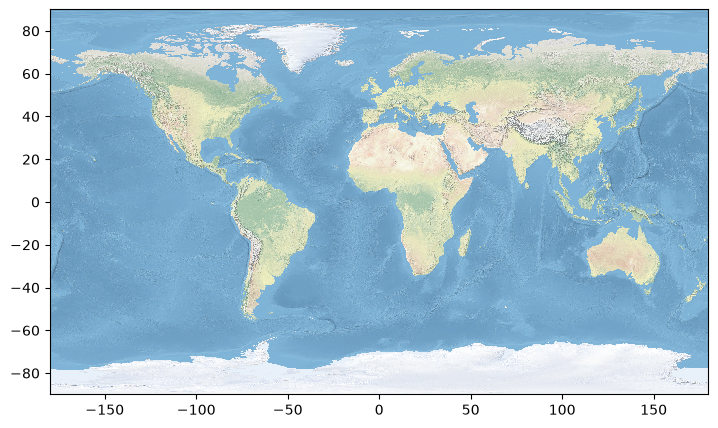

In [69]:
relief_url = ("MappingFiles/NE1_50M_SR_W/NE1_50M_SR_W.tif")
relief = rioxarray.open_rasterio(relief_url)

# make your plot
fig, ax = plt.subplots()
fig.set_size_inches(8.5, 5)

# Subsample every 4th pixel for fast plotting; xarray keeps x/y coordinates attached
relief[:, ::4, ::4].plot.imshow(ax=ax, rgb="band", add_labels=False)


### Put it together
- Plot one over the other to make a great map!  

(-90.0, 90.0)

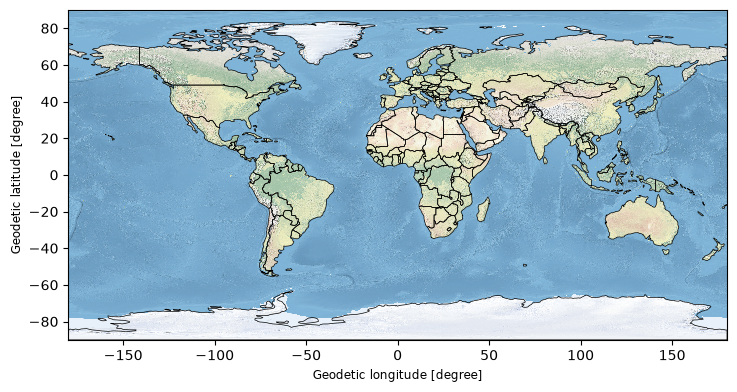

In [111]:
# readin in world data
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)

# readin relief
relief_url = ("MappingFiles/NE1_50M_SR_W/NE1_50M_SR_W.tif")
relief = rioxarray.open_rasterio(relief_url)

# make the fig
fig, ax = plt.subplots()
fig.set_size_inches(8.5, 5)

# Subsample every 4th pixel for fast plotting; xarray keeps x/y coordinates attached
relief[:, ::4, ::4].plot.imshow(ax=ax, rgb="band", add_labels=False)

# Plot land and country borders
world.plot(ax=ax, color="none", edgecolor="black", linewidth=0.5)

# Clamp to true global coordinates 
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)


Text(0.5, 1.0, 'United States Shaded Relief')

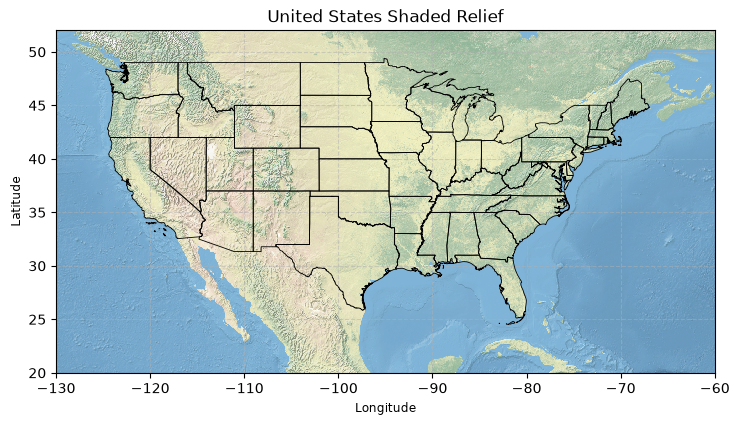

In [112]:
# 1. Clip your existing global elevation raster to the continental US box
relief_url = ("MappingFiles/NE1_50M_SR_W/NE1_50M_SR_W.tif")
relief = rioxarray.open_rasterio(relief_url)
us_relief = relief.rio.clip_box(minx=-130, miny=20, maxx=-60, maxy=52)

# 2. Load the US states 
states = gpd.read_file("MappingFiles/cb_2016_us_state_5m/cb_2016_us_state_5m.shp").to_crs(
    "EPSG:4326")

# 3. Plot clipped elevation + state borders
fig, ax = plt.subplots()
fig.set_size_inches(8.5, 5)

us_relief.plot.imshow(ax=ax, rgb="band", add_labels=False)
states.boundary.plot(ax=ax, color="black", linewidth=0.6)

ax.set_xlim(-130, -60)
ax.set_ylim(20, 52)
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("United States Shaded Relief")

### Cut out the US!

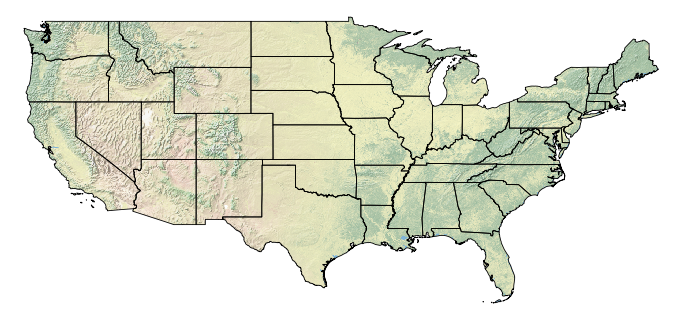

In [113]:
# 1. Clip your existing global elevation raster to the continental US box
relief_url = ("MappingFiles/NE1_50M_SR_W/NE1_50M_SR_W.tif")
relief = rioxarray.open_rasterio(relief_url)
us_relief = relief.rio.clip_box(minx=-130, miny=20, maxx=-60, maxy=52)

# 2. Load US states and filter to the lower 48
states = gpd.read_file("MappingFiles/cb_2016_us_state_5m/cb_2016_us_state_5m.shp").to_crs(
    "EPSG:4326")
lower48 = states[~states["NAME"].isin(["Alaska", "Hawaii", "Puerto Rico"])]

# 3. Convert uint8 (0-255) to float32 (0.0-1.0) BEFORE clipping so outside pixels become transparent NaNs
us_only_relief = (us_relief.astype("float32") / 255.0).rio.clip(
    lower48.geometry, lower48.crs
)

# 4. Plot clipped elevation + state borders
fig, ax = plt.subplots()
fig.set_size_inches(8.5, 5)

us_only_relief.plot.imshow(ax=ax, rgb="band", add_labels=False)
lower48.boundary.plot(ax=ax, color="black", linewidth=0.6)

# Tighten the view slightly around the lower 48 and hide all axes/frames
ax.set_xlim(-126, -66)
ax.set_ylim(24, 50)
ax.set_axis_off()

## Addinng points to a map.
- Read the excel file of CO2 Stations

In [75]:
df_CO2=pd.read_excel('MappingFiles/Mapping.xlsx',sheet_name="CO2Stations")

In [76]:
df_CO2

,StationName,StationCode,Latitude,Longitude,Elevation,Dates
0,"Alert, NWT, Canada",ALT,82.3,-62.3,210,1985 - present
1,"Point Barrow, Alaska",PTB,71.3,-156.6,11,1961 - present
2,"La Jolla Pier, California",LJO,32.9,-117.3,10,1957 - present
3,"Mauna Loa Observatory, Hawaii",MLO,19.5,-155.6,3397,1958 - present
4,"Cape Kumukahi, Hawaii",KUM,19.5,-154.8,3,1979 - present
5,Christmas Island,CHR,2.0,-157.3,2,1974 - present
6,American Samoa,SAM,-14.2,-170.6,30,1981 - present
7,Kermadec Island,KER,-29.2,-177.9,2,1982 -present
8,"Baring Head, New Zealand",NZD,-41.4,174.9,85,1977 - present
9,South Pole,SPO,-90.0,-90.0,2810,1957 - present


### Convert to geopandas
- we will call it gdf 

In [119]:
# readin
df_CO2=pd.read_excel('MappingFiles/Mapping.xlsx',sheet_name="CO2Stations")

# convert
gdf = gpd.GeoDataFrame(
    df_CO2,
    geometry=gpd.points_from_xy(df_CO2["Longitude"], df_CO2["Latitude"]),
    crs="EPSG:4326",
)

In [80]:
gdf

,StationName,StationCode,Latitude,Longitude,Elevation,Dates,geometry
0,"Alert, NWT, Canada",ALT,82.3,-62.3,210,1985 - present,POINT (-62.3 82.3)
1,"Point Barrow, Alaska",PTB,71.3,-156.6,11,1961 - present,POINT (-156.6 71.3)
2,"La Jolla Pier, California",LJO,32.9,-117.3,10,1957 - present,POINT (-117.3 32.9)
3,"Mauna Loa Observatory, Hawaii",MLO,19.5,-155.6,3397,1958 - present,POINT (-155.6 19.5)
4,"Cape Kumukahi, Hawaii",KUM,19.5,-154.8,3,1979 - present,POINT (-154.8 19.5)
5,Christmas Island,CHR,2.0,-157.3,2,1974 - present,POINT (-157.3 2)
6,American Samoa,SAM,-14.2,-170.6,30,1981 - present,POINT (-170.6 -14.2)
7,Kermadec Island,KER,-29.2,-177.9,2,1982 -present,POINT (-177.9 -29.2)
8,"Baring Head, New Zealand",NZD,-41.4,174.9,85,1977 - present,POINT (174.9 -41.4)
9,South Pole,SPO,-90.0,-90.0,2810,1957 - present,POINT (-90 -90)


### Just plot the points

<Axes: title={'center': 'World Map (EPSG:4326)'}, xlabel='Longitude', ylabel='Latitude'>

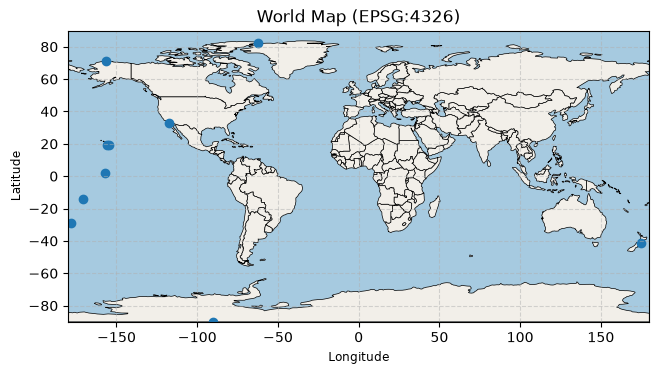

In [120]:
# readin
df_CO2=pd.read_excel('MappingFiles/Mapping.xlsx',sheet_name="CO2Stations")

# convert
gdf = gpd.GeoDataFrame(
    df_CO2,
    geometry=gpd.points_from_xy(df_CO2["Longitude"], df_CO2["Latitude"]),
    crs="EPSG:4326",
)

# readin in world data
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)

fig, ax = plt.subplots()
fig.set_size_inches(7.5, 5)

# Plot land and country borders
world.plot(ax=ax, color="#f2efe9", edgecolor="black", linewidth=0.5)

# Clamp to true global coordinates (eliminates the blue gap below Antarctica)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)

# Add ocean background and gridlines
ax.set_facecolor("#a6cae0")
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("World Map (EPSG:4326)")

gdf.plot(ax=ax)

### You can adjust like any other plot

<Axes: title={'center': 'World Map (EPSG:4326)'}, xlabel='Longitude', ylabel='Latitude'>

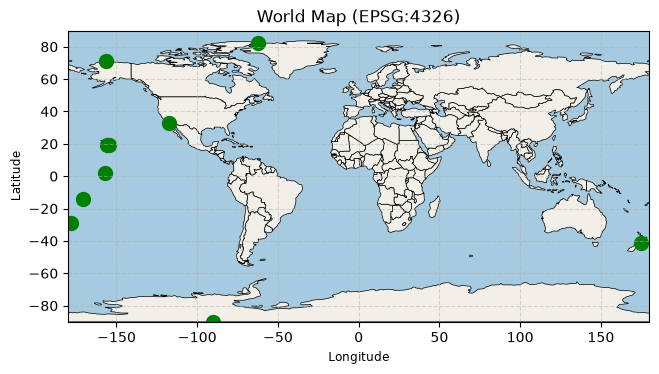

In [121]:
# readin
df_CO2=pd.read_excel('MappingFiles/Mapping.xlsx',sheet_name="CO2Stations")

# convert
gdf = gpd.GeoDataFrame(
    df_CO2,
    geometry=gpd.points_from_xy(df_CO2["Longitude"], df_CO2["Latitude"]),
    crs="EPSG:4326",
)

# readin in world data
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)

fig, ax = plt.subplots()
fig.set_size_inches(7.5, 5)

# Plot land and country borders
world.plot(ax=ax, color="#f2efe9", edgecolor="black", linewidth=0.5)

# Clamp to true global coordinates (eliminates the blue gap below Antarctica)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)

# Add ocean background and gridlines
ax.set_facecolor("#a6cae0")
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("World Map (EPSG:4326)")

gdf.plot(ax=ax,
        markersize=100,
        color='green')

### you can color by a different coloumn or parameter.  We will do elevation

<Axes: xlabel='Longitude', ylabel='Latitude'>

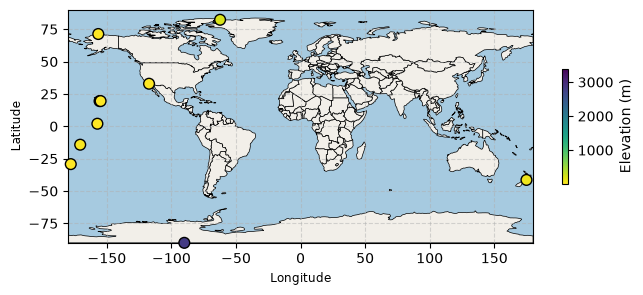

In [122]:
# readin
df_CO2=pd.read_excel('MappingFiles/Mapping.xlsx',sheet_name="CO2Stations")

# convert
gdf = gpd.GeoDataFrame(
    df_CO2,
    geometry=gpd.points_from_xy(df_CO2["Longitude"], df_CO2["Latitude"]),
    crs="EPSG:4326",
)

# readin in world data
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)

fig, ax = plt.subplots()
fig.set_size_inches(7.5, 5)

# Plot land and country borders
world.plot(ax=ax, color="#f2efe9", edgecolor="black", linewidth=0.5)

# Clamp to true global coordinates (eliminates the blue gap below Antarctica)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)

# Add ocean background and gridlines
ax.set_facecolor("#a6cae0")
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

gdf.plot(ax=ax,
    column="Elevation",
    cmap="viridis_r",
    markersize=60,
    edgecolor="black",
    legend=True,
    legend_kwds={"label": "Elevation (m)", "shrink": 0.3},
    clip_on=False,
    zorder=5,)

### Annotating is a pain!
- You need iterrows.
    - You iterate over the rows. 
- You go through a dataframe row by row.
- it gives you an index and then the row informtion for each row.
- here is an exampling

In [84]:
for idx, row in gdf.iterrows():
    print(f'idx={idx} \n row_data\n{row}\n')

idx=0 
 row_data
StationName    Alert, NWT, Canada
StationCode                   ALT
Latitude                     82.3
Longitude                   -62.3
Elevation                     210
Dates              1985 - present
geometry       POINT (-62.3 82.3)
Name: 0, dtype: object

idx=1 
 row_data
StationName    Point Barrow, Alaska
StationCode                     PTB
Latitude                       71.3
Longitude                    -156.6
Elevation                        11
Dates                1961 - present
geometry        POINT (-156.6 71.3)
Name: 1, dtype: object

idx=2 
 row_data
StationName    La Jolla Pier, California
StationCode                          LJO
Latitude                            32.9
Longitude                         -117.3
Elevation                             10
Dates                     1957 - present
geometry             POINT (-117.3 32.9)
Name: 2, dtype: object

idx=3 
 row_data
StationName    Mauna Loa Observatory, Hawaii
StationCode                           

### Now we will just use the Name and locations

In [85]:
for idx, row in gdf.iterrows():
    print(row['StationName'])

Alert, NWT, Canada
Point Barrow, Alaska
La Jolla Pier, California
Mauna Loa Observatory, Hawaii
Cape Kumukahi, Hawaii
Christmas Island
American Samoa
Kermadec Island
Baring Head, New Zealand
South Pole


### Now we can add the name and its location and plot it

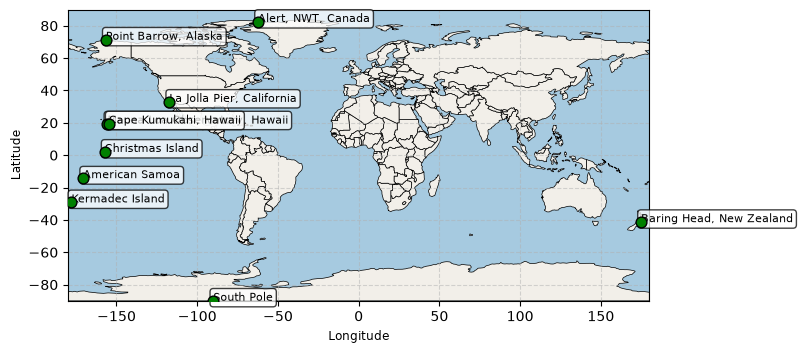

In [123]:
# readin
df_CO2=pd.read_excel('MappingFiles/Mapping.xlsx',sheet_name="CO2Stations")

# convert
gdf = gpd.GeoDataFrame(
    df_CO2,
    geometry=gpd.points_from_xy(df_CO2["Longitude"], df_CO2["Latitude"]),
    crs="EPSG:4326",
)

# readin in world data
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)

fig, ax = plt.subplots()
fig.set_size_inches(7.5, 5)

# Plot land and country borders
world.plot(ax=ax, color="#f2efe9", edgecolor="black", linewidth=0.5)

# Clamp to true global coordinates (eliminates the blue gap below Antarctica)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)

# Add ocean background and gridlines
ax.set_facecolor("#a6cae0")
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

gdf.plot(ax=ax,
    markersize=60,
    edgecolor="black",
    color='green',
    zorder=5,)

for idx, row in gdf.iterrows():
  ax.annotate(
      row["StationName"],
      xy=(row["Longitude"], row["Latitude"]),
      fontsize=8,
      bbox=dict(boxstyle="round", facecolor="white", alpha=0.75),
  )

### Add an offset and your map is looking really nice!

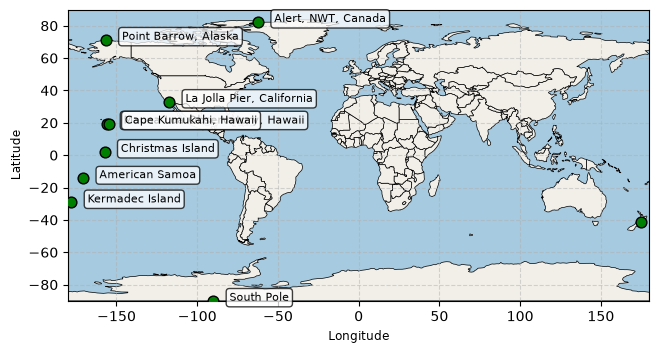

In [124]:
# readin
df_CO2=pd.read_excel('MappingFiles/Mapping.xlsx',sheet_name="CO2Stations")

# convert
gdf = gpd.GeoDataFrame(
    df_CO2,
    geometry=gpd.points_from_xy(df_CO2["Longitude"], df_CO2["Latitude"]),
    crs="EPSG:4326",
)

# readin in world data
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)

fig, ax = plt.subplots()
fig.set_size_inches(7.5, 5)

# Plot land and country borders
world.plot(ax=ax, color="#f2efe9", edgecolor="black", linewidth=0.5)

# Clamp to true global coordinates (eliminates the blue gap below Antarctica)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)

# Add ocean background and gridlines
ax.set_facecolor("#a6cae0")
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

gdf.plot(ax=ax,
    markersize=60,
    edgecolor="black",
    color='green',
    zorder=5,)

for idx, row in gdf.iterrows():
  ax.annotate(
      row["StationName"],
      xy=(row["Longitude"]+10, row["Latitude"]),
      fontsize=8,
      bbox=dict(boxstyle="round", facecolor="white", alpha=0.75),
  )

### I think that looks pretty good!  
- I am not worrying about overlaps.
- Let's see if AI can make us a map without overlaps and centered on the pacific
- get your versions

In [48]:
import matplotlib
import platform
import sys
import seaborn 
import geopandas 

# Detect macOS reliably across all Mac models
os_name = "macOS" if sys.platform == "darwin" else platform.system()

# Safely check JupyterLab version if installed in the current kernel
try:
  import jupyterlab

  jl_ver = jupyterlab.__version__
except ImportError:
  jl_ver = "4.x"  # Fallback estimate

prompt_text = (
    f"I am running Python {sys.version.split()[0]} with Matplotlib "
    f"{matplotlib.__version__}, Searbon {seaborn.__version__}, " 
    f"and GeoPandas {geopandas.__version__} in JupyterLab {jl_ver} on {os_name}. "
    f"Please write code compatible with these versions."
)

print(prompt_text)

I am running Python 3.11.15 with Matplotlib 3.11.1, Searbon 0.13.2, and GeoPandas 1.2.0 in JupyterLab 4.6.3 on macOS. Please write code compatible with these versions.


### Make a nice map using geopandas.  Try my prompt but with your info.  See what you get!!!!

"Write a complete Python script using `geopandas' to create a high-resolution, publication-quality map in a single Jupyter notebook cell.   Use fig,ax=plt.subplots()

I am running Python 3.11.15 with Matplotlib 3.11.1, Searbon 0.13.2, and GeoPandas 1.2.0 in JupyterLab 4.6.3 on macOS. Please write code compatible with these versions.
    
Make a map of the world showin the location of the CO2 sampling stations
- The CO2 sampling stations are in the file  'CO2Stations.xlsx' 
- Show the stations on a world map
- Label each station with the StationName
- Center the map on the Pacific Ocean and the stations
- save the map to a unique filename
- Make suggestions for how to improve the figure. 

Saved high-resolution map to: co2_stations_pacific_map_20261117_145332_ad4f12.png


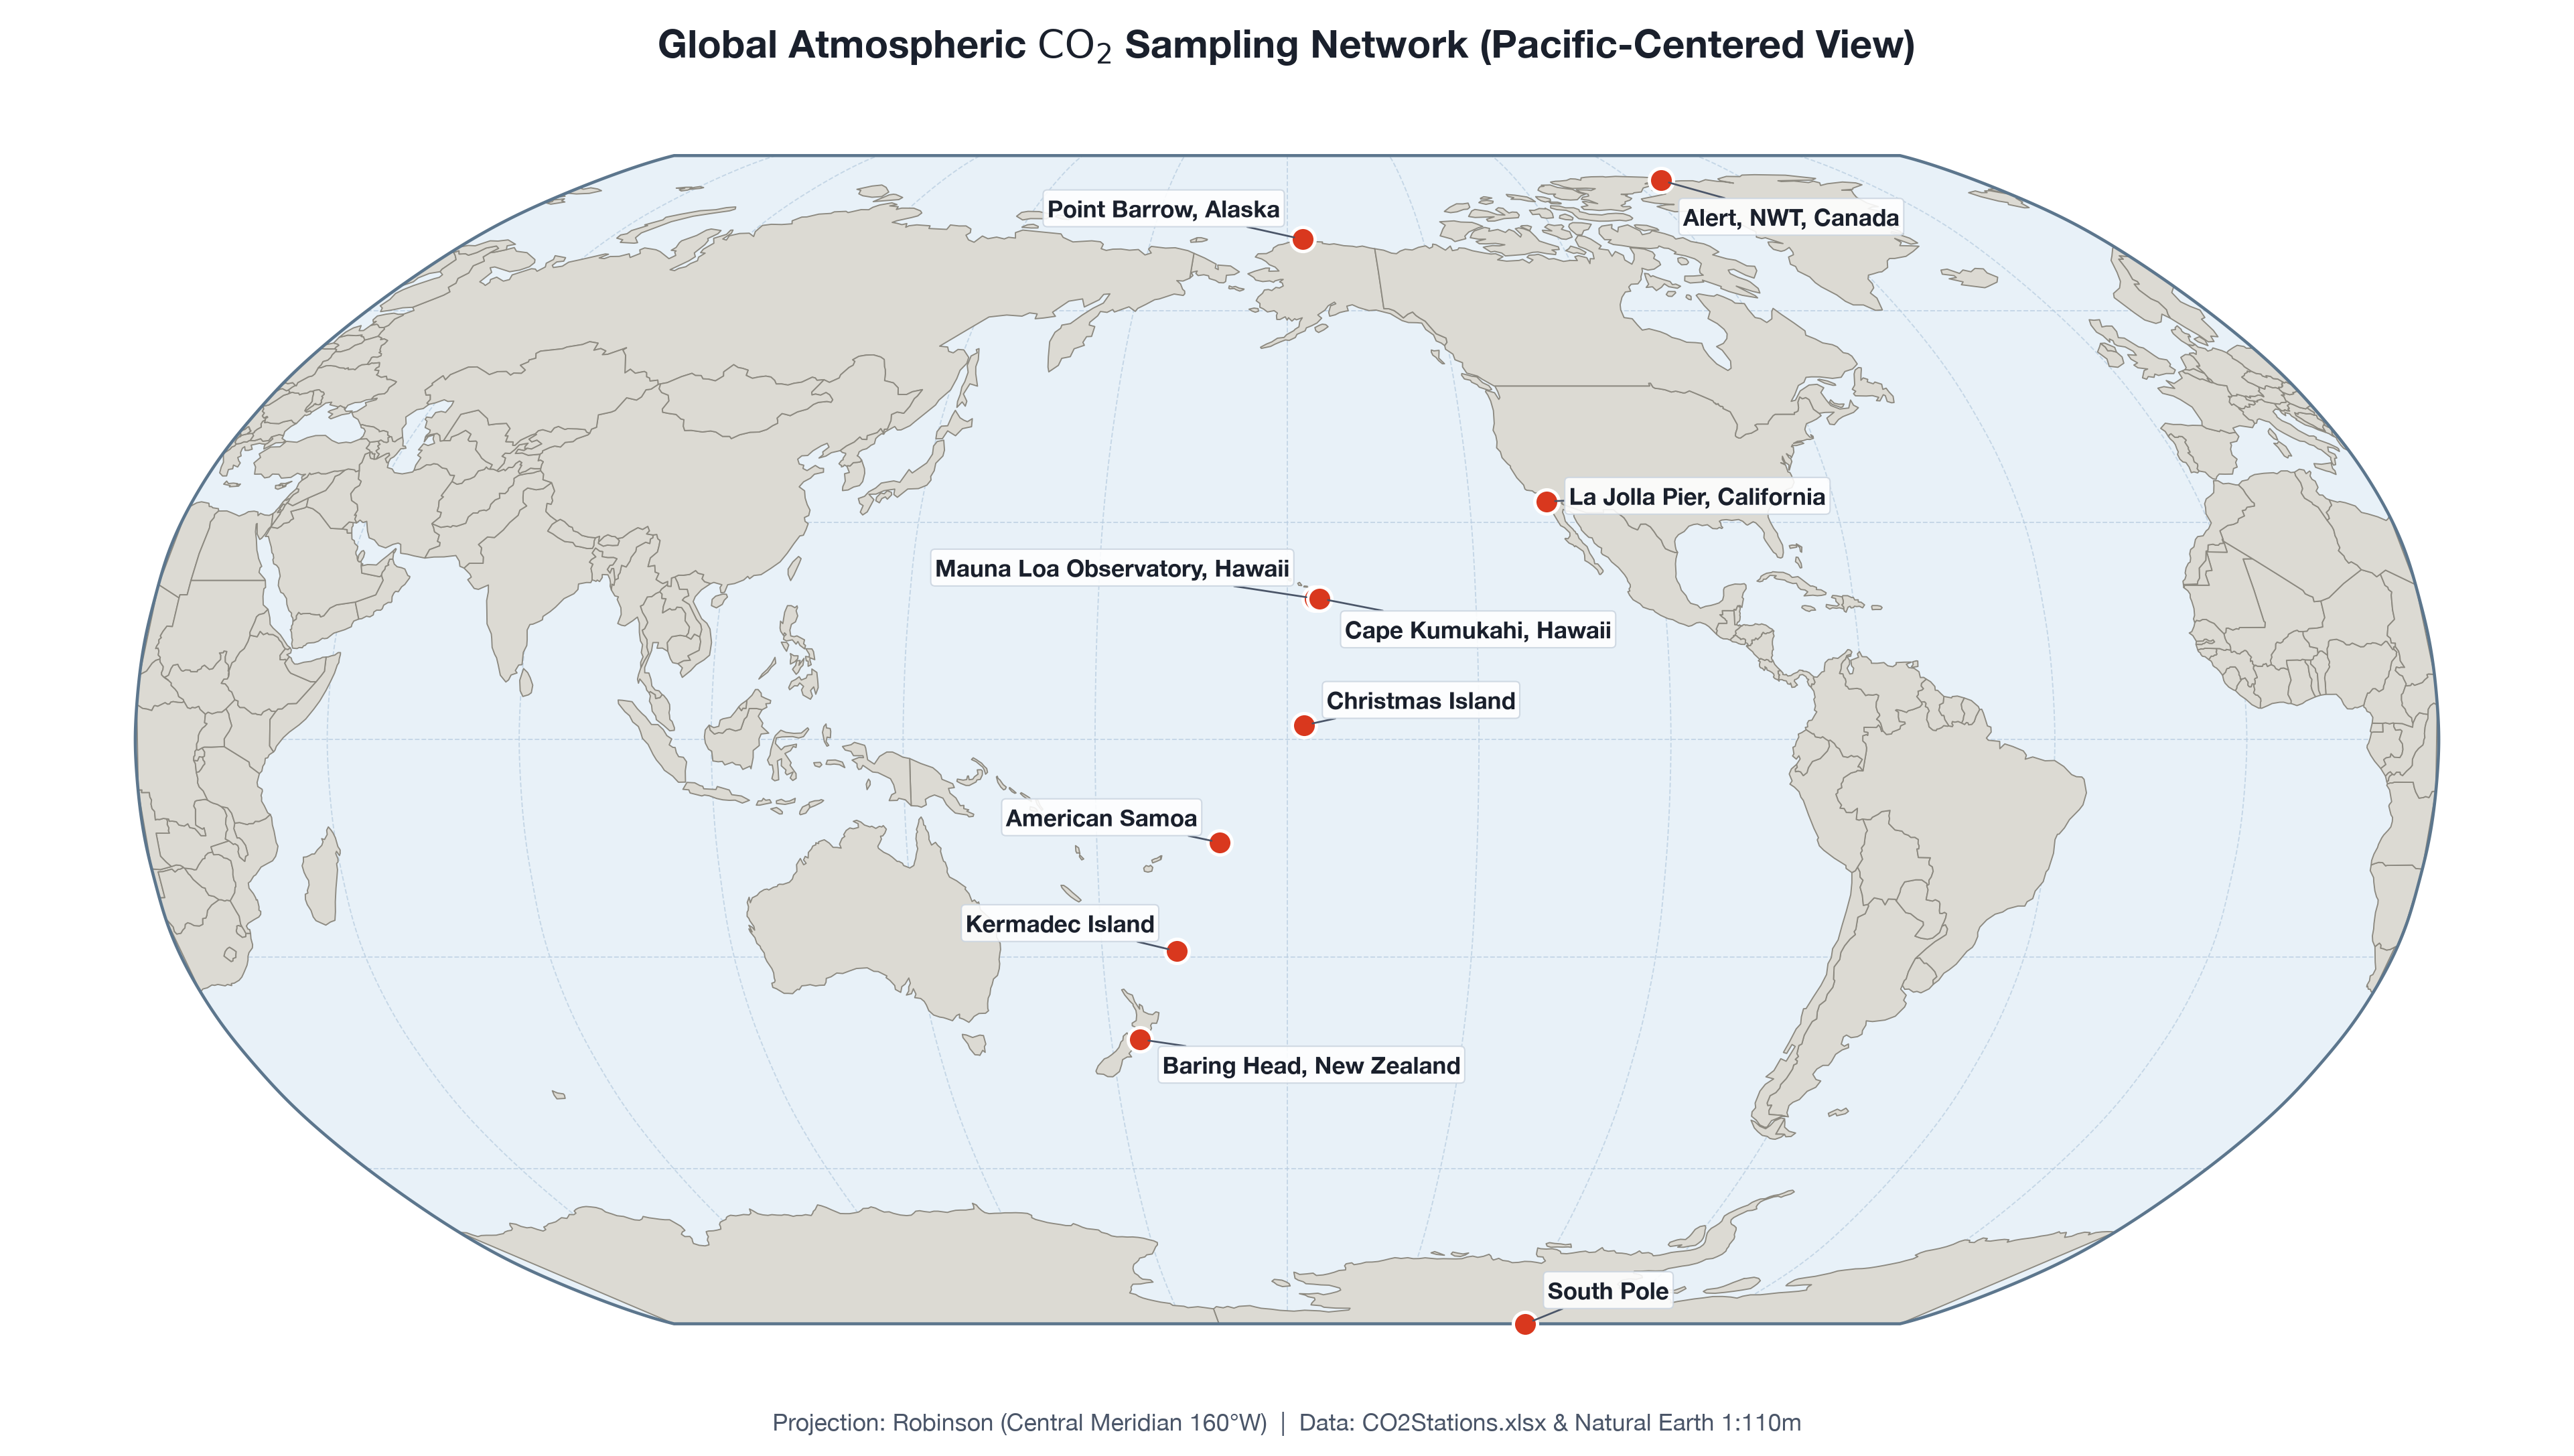

In [50]:
from datetime import datetime
import uuid
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from shapely.geometry import LineString, Polygon, box

# 1. Configure publication styling (Seaborn 0.13.2 + Matplotlib 3.11.1)
sns.set_theme(style="white", context="paper", font_scale=1.15)
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "axes.edgecolor": "#4a5568",
    "axes.linewidth": 0.8,
})

# 2. Load CO2 station metadata from Excel
stations_df = pd.read_excel("CO2Stations.xlsx", sheet_name="Sheet1")
stations_gdf = gpd.GeoDataFrame(
    stations_df,
    geometry=gpd.points_from_xy(
        stations_df["Longitude"], stations_df["Latitude"]
    ),
    crs="EPSG:4326",
)

# 3. Load Natural Earth 1:110m country boundaries (GeoPandas 1.2.0 compatible;
#    gpd.datasets was removed in GeoPandas 1.0)
ne_url = (
    "https://naciscdn.org/naturalearth/110m/cultural/"
    "ne_110m_admin_0_countries.zip"
)
world = gpd.read_file(ne_url)

# 4. Set up Pacific-centered Robinson projection (160°W central meridian)
lon_0 = -160.0  # Centers the Pacific Ocean and the sampling transect
cut_lon = lon_0 + 180.0  # Opposite meridian (+20°E) where the globe splits
target_crs = f"+proj=robin +lon_0={lon_0} +x_0=0 +y_0=0 +datum=WGS84 +units=m +no_defs"

# Split world polygons along +20°E before reprojecting to prevent wrap-around streaks
eps = 1e-4
west_hemisphere = gpd.clip(world, box(-180.0, -90.0, cut_lon - eps, 90.0))
east_hemisphere = gpd.clip(world, box(cut_lon + eps, -90.0, 180.0, 90.0))
world_pacific = pd.concat(
    [west_hemisphere, east_hemisphere], ignore_index=True
).to_crs(target_crs)

stations_proj = stations_gdf.to_crs(target_crs)

# 5. Construct true curved Robinson globe outline and subtle graticules
lats = np.linspace(-90.0, 90.0, 361)
globe_coords = [(cut_lon + eps, lat) for lat in lats] + [
    (cut_lon - eps, lat) for lat in lats[::-1]
]
globe_gdf = gpd.GeoDataFrame(
    geometry=[Polygon(globe_coords)], crs="EPSG:4326"
).to_crs(target_crs)

graticule_lines = []
for lat in [-60, -30, 0, 30, 60]:
    graticule_lines.append(
        LineString([(lon, lat) for lon in np.linspace(-180.0, cut_lon - eps, 180)])
    )
    graticule_lines.append(
        LineString([(lon, lat) for lon in np.linspace(cut_lon + eps, 180.0, 180)])
    )
for lon in [-160, -130, -100, -70, -40, -10, 50, 80, 110, 140, 170]:
    graticule_lines.append(LineString([(lon, lat) for lat in lats]))

graticules_gdf = gpd.GeoDataFrame(
    geometry=graticule_lines, crs="EPSG:4326"
).to_crs(target_crs)

# 6. Build the figure using fig, ax = plt.subplots()
fig, ax = plt.subplots(figsize=(14, 7.5), dpi=300)

# Plot ocean background, graticules, landmasses, and globe border
globe_gdf.plot(ax=ax, facecolor="#e8f1f8", edgecolor="none", zorder=1)
graticules_gdf.plot(
    ax=ax, color="#b8cde0", linewidth=0.45, linestyle="--", alpha=0.75, zorder=2
)
world_pacific.plot(
    ax=ax, facecolor="#dcdad3", edgecolor="#8c8980", linewidth=0.45, zorder=3
)
globe_gdf.boundary.plot(ax=ax, color="#5c768d", linewidth=1.1, zorder=4)

# Plot CO2 sampling stations
stations_proj.plot(
    ax=ax,
    color="#d9381e",
    edgecolor="white",
    linewidth=1.2,
    markersize=75,
    zorder=6,
)

# 7. Custom label offsets (dx, dy in points, horizontal & vertical alignment)
#    Prevents overlaps between nearby stations (especially Mauna Loa & Cape Kumukahi)
label_offsets = {
    "ALT": (8, -8, "left", "top"),       # Alert, NWT, Canada
    "PTB": (-8, 6, "right", "bottom"),   # Point Barrow, Alaska
    "LJO": (8, 2, "left", "center"),     # La Jolla Pier, California
    "MLO": (-9, 6, "right", "bottom"),   # Mauna Loa Observatory, Hawaii
    "KUM": (9, -6, "left", "top"),       # Cape Kumukahi, Hawaii
    "CHR": (8, 4, "left", "bottom"),     # Christmas Island
    "SAM": (-8, 4, "right", "bottom"),   # American Samoa
    "KER": (-8, 5, "right", "bottom"),   # Kermadec Island
    "NZD": (8, -4, "left", "top"),       # Baring Head, New Zealand
    "SPO": (8, 7, "left", "bottom"),     # South Pole
}

for _, row in stations_proj.iterrows():
    code = row["StationCode"]
    dx, dy, ha, va = label_offsets.get(code, (7, 5, "left", "bottom"))
    ax.annotate(
        row["StationName"],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(dx, dy),
        textcoords="offset points",
        ha=ha,
        va=va,
        fontsize=8.5,
        fontweight="semibold",
        color="#1a202c",
        zorder=7,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="white",
            edgecolor="#cbd5e0",
            alpha=0.88,
            linewidth=0.5,
        ),
        arrowprops=dict(
            arrowstyle="-",
            color="#4a5568",
            linewidth=0.65,
            shrinkA=0,
            shrinkB=3,
        ),
    )

# 8. Titles, attribution, and clean layout
ax.set_title(
    "Global Atmospheric $\\mathrm{CO}_2$ Sampling Network (Pacific-Centered View)",
    fontsize=14,
    fontweight="bold",
    color="#1a202c",
    pad=14,
)
fig.text(
    0.5,
    0.04,
    "Projection: Robinson (Central Meridian 160°W)  |  Data: CO2Stations.xlsx & Natural Earth 1:110m",
    ha="center",
    fontsize=8.5,
    color="#4a5568",
)
ax.set_axis_off()
plt.tight_layout(rect=[0, 0.05, 1, 0.98])

# 9. Save to a unique timestamped filename and render in JupyterLab
unique_id = f"{datetime.now():%Y%m%d_%H%M%S}_{uuid.uuid4().hex[:6]}"
output_filename = f"co2_stations_pacific_map_{unique_id}.png"
fig.savefig(output_filename, dpi=600, bbox_inches="tight", facecolor="white")
print(f"Saved high-resolution map to: {output_filename}")
plt.show()

# Next topic

# Interactive Map!
- This is just cool
- You make an interactive map that you can open in any web browser
- All the same.  Just call explore instead!
- This then calls folium which creates the map.
- you will have an html file in your folder you can open

In [87]:
# 1. Read the "Sheffield" tab from the Excel file
df_sheffield = pd.read_excel("MappingFiles/Mapping.xlsx", sheet_name="Sheffield")

# 2. Convert to a GeoDataFrame (Longitude = x, Latitude = y)
gdf_sheffield = gpd.GeoDataFrame(
    df_sheffield,
    geometry=gpd.points_from_xy(
        df_sheffield["Longitude"], df_sheffield["Latitude"]
    ),
    crs="EPSG:4326",
)

# 3. Create the interactive Folium map (automatically centers & zooms to fit all 5 points)
m = gdf_sheffield.explore(
    marker_type="marker",  # Classic teardrop pins (or use "circle_marker")
    tooltip="Location",  # Shows location name when hovering
    popup=True,  # Opens a table of all columns when clicked
    tiles="Esri.WorldStreetMap"#"OpenStreetMap",  # Or try "CartoDB positron"
)

# 4. Save as a standalone HTML file (for Homework Q3) and display
m.save("Sheffield.html")
m

# Next Topic

# Choropleths
- Defintion: From Wikipedia: A choropleth map is a statistical thematic map that fills pre-defined geographic areas (such as states, counties, or countries) with colors or patterns proportional to a data variable
- Lead data from here
    - Hauptman M, Niles JK, Gudin J, Kaufman HW. Individual- and Community-Level Factors Associated With Detectable and Elevated Blood Lead Levels in US Children: Results From a National Clinical Laboratory. JAMA Pediatr. 2021;175(12):1252–1260. doi:10.1001/jamapediatrics.2021.3518
 
#### First read the blood lead data from the states in a table

In [89]:
# 1. Read the lead dataset from Mapping.xlsx (note the exact tab spelling: "StaePbData")
df_pb = pd.read_excel("MappingFiles/Mapping.xlsx", sheet_name="QuestData")


#### Second Read the states shapefile and get rid of any states outside the lower 48

In [90]:
# 1. Read the lead dataset from Mapping.xlsx (note the exact tab spelling: "StaePbData")
df_pb = pd.read_excel("MappingFiles/Mapping.xlsx", sheet_name="QuestData")

# 2. Load US state boundaries and filter to the contiguous lower 48 + DC
states = gpd.read_file("MappingFiles/cb_2016_us_state_5m/cb_2016_us_state_5m.shp").to_crs(
    "EPSG:4326"
)
lower48 = states[
    ~states["NAME"].isin([
        "Alaska",
        "Hawaii",
        "Puerto Rico",
        "American Samoa",
        "Guam",
        "Commonwealth of the Northern Mariana Islands",
        "United States Virgin Islands",
    ])
]

#### Third.  This is critical.  Merge the two datasets on the columns that list the states.

In [91]:
# 1. Read the lead dataset from Mapping.xlsx (note the exact tab spelling: "StaePbData")
df_pb = pd.read_excel("MappingFiles/Mapping.xlsx", sheet_name="QuestData")

# 2. Load US state boundaries and filter to the contiguous lower 48 + DC
states = gpd.read_file("MappingFiles/cb_2016_us_state_5m/cb_2016_us_state_5m.shp").to_crs(
    "EPSG:4326"
)
lower48 = states[
    ~states["NAME"].isin([
        "Alaska",
        "Hawaii",
        "Puerto Rico",
        "American Samoa",
        "Guam",
        "Commonwealth of the Northern Mariana Islands",
        "United States Virgin Islands",
    ])
]

# 3. Merge on full state name (how="left" keeps states with missing/NaN values)
gdf_pb = lower48.merge(df_pb, left_on="NAME", right_on="State", how="left")

#### Finally plot the data!!!

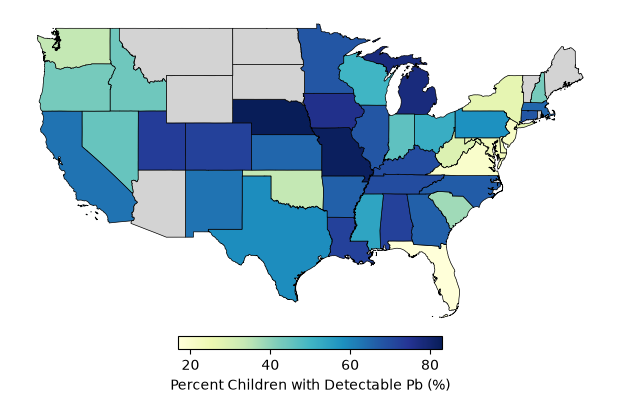

In [92]:
# 1. Read the lead dataset from Mapping.xlsx (note the exact tab spelling: "StaePbData")
df_pb = pd.read_excel("MappingFiles/Mapping.xlsx", sheet_name="QuestData")

# 2. Load US state boundaries and filter to the contiguous lower 48 + DC
states = gpd.read_file("MappingFiles/cb_2016_us_state_5m/cb_2016_us_state_5m.shp").to_crs(
    "EPSG:4326"
)
lower48 = states[
    ~states["NAME"].isin([
        "Alaska",
        "Hawaii",
        "Puerto Rico",
        "American Samoa",
        "Guam",
        "Commonwealth of the Northern Mariana Islands",
        "United States Virgin Islands",
    ])
]

# 3. Merge on full state name (how="left" keeps states with missing/NaN values)
gdf_pb = lower48.merge(df_pb, left_on="NAME", right_on="State", how="left")

# 4. Plot the static choropleth map
fig, ax = plt.subplots()
fig.set_size_inches(8.5, 5)

gdf_pb.plot(
    column="Detectable_BLL_Pct",
    ax=ax,
    cmap="YlGnBu",  # Or "YlGn" / "OrRd"
    edgecolor="black",
    linewidth=0.5,
    legend=True,
    legend_kwds={"label": "Percent Children with Detectable Pb (%)",
                 "shrink": 0.4,
                "orientation": "horizontal",
                "pad":0.01},
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "label": "No Data"},
)

ax.set_axis_off()


# Raster Data

## Now something really cool. Lets plot surface temperatures on the day we were born!!!!  Or any other day you choose!

We will use this NOAA website to retrieve the data.
https://psl.noaa.gov/data/composites/day/
-  Choose Variable ->air temperature
-  choose anaylis level -> surface
-  add your birthday to a box.  look at order it is year-month-day
-  move down and do plot type mean
-  do region of globe all
-  press create plot
-  just enjoy the graph/map.  But we want to do better on python. 
-  make sure it is the correct date and parameter
-  Click on "Get a copy of the netCDF data file used for the plot"
-  This will downlaod the netcdf file
-  move the NetCDF file to the directory where you work and we are readyto work!
-  Do the next two cells and then try to read the metadata and make sense of it!



### NetCDF

You can learn about NetCDF at https://www.unidata.ucar.edu/software/netcdf/.  From the website.  "NetCDF (Network Common Data Form) is a set of software libraries and machine-independent data formats that support the creation, access, and sharing of array-oriented scientific data. It is also a community standard for sharing scientific data. The Unidata Program Center supports and maintains netCDF programming interfaces for C, C++, Java, and Fortran. Programming interfaces are also available for Python, IDL, MATLAB, R, Ruby, and Perl."

This is going to be weird to you.  netcdf files are in binary format so you can never "see" them.  I feel like csv files are intuitive.  You can see the columns.  NetCDF files are have headers that tell you what is in them.  I see them a lot with spatial data for example sea surface temperatures.  But they also have a funny format.  They list types of data one at a time and not in a table.  So it is all latitude data, then all longitude data, then all time data, then all temperature data etc.   It takes get used to.   



#### In the past students have told me that they have stood out in internships becuase they knew about NetCDF files. 

So lets start.  file is the name of the file you downloaded

You read the data into a parameter called f.  This is just what people do.  f then contains all the information you need.  it is sort of like a dataframe for netcdf but you never see the data.  you probe at it.

#### This is how you read the header

In [93]:
ds = xr.open_dataset("MappingFiles/compday.0MMqOx1iJi.nc")
ds  # Displays interactive HTML summary of Dimensions, Coordinates, Data variables, and Attributes

<xarray.Dataset> Size: 43kB
Dimensions:  (time: 1, lat: 73, lon: 144)
Coordinates:
  * time     (time) datetime64[ns] 8B 1972-02-24
  * lat      (lat) float32 292B 90.0 87.5 85.0 82.5 ... -82.5 -85.0 -87.5 -90.0
  * lon      (lon) float32 576B 0.0 2.5 5.0 7.5 10.0 ... 350.0 352.5 355.0 357.5
Data variables:
    air      (time, lat, lon) float32 42kB ...
Attributes:
    title:        Composite Value
    history:      Created via daily composite webtool at NOAA/PSL
    description:  Computed from the web page https://psl.noaa.gov//data/compo...
    Conventions:  COARDS

### Now Just use this script to get more information about the file.

In [25]:
# 1. Global Attributes: who made the file, when, and under what standard?
print("--- GLOBAL ATTRIBUTES (File-Level Provenance) ---")
for key, val in ds.attrs.items():
  print(f"  {key}: {val}")

# 2. Dimensions: the shape of the 3D data cube
print("\n--- DIMENSIONS (Grid Axes) ---")
print(f"  {dict(ds.sizes)}")

# 3. Coordinate Variables: physical locations & timestamps along each axis
print("\n--- COORDINATES ---")
for coord_name, coord in ds.coords.items():
  print(
      f"  {coord_name} {coord.dims}: {coord.attrs.get('long_name')} "
      f"[{coord.attrs.get('units', 'datetime')}] -> "
      f"{coord.values[0]} to {coord.values[-1]}"
  )

# 4. Data Variable & Variable Attributes: what is actually measured?
print("\n--- DATA VARIABLE ('air') ATTRIBUTES ---")
for key, val in ds["air"].attrs.items():
  print(f"  {key}: {val}")

--- GLOBAL ATTRIBUTES (File-Level Provenance) ---
  title: Composite Value
  history: Created via daily composite webtool at NOAA/PSL
  description: Computed from the web page https://psl.noaa.gov//data/composites/day/ NOAA/PSL
  Conventions: COARDS

--- DIMENSIONS (Grid Axes) ---
  {'time': 1, 'lat': 73, 'lon': 144}

--- COORDINATES ---
  lat ('lat',): Latitude [degrees_north] -> 90.0 to -90.0
  lon ('lon',): Longitude [degrees_east] -> 0.0 to 357.5
  time ('time',): Time [datetime] -> 1972-02-24T00:00:00.000000000 to 1972-02-24T00:00:00.000000000

--- DATA VARIABLE ('air') ATTRIBUTES ---
  long_name: Air Temperature
  actual_range: [ 93.03 377.2 ]
  units: degK
  precision: 99
  least_significant_digit: 99
  var_desc: Air Temperature
  dataset: CDC Derived NCEP Reanalysis Products
  level_desc: Surface
  statistic: Composite
  parent_stat: Other


#### We are going to put it together to make a plot.  
- Open the file
- Convert to Celcius
- change the units name (AI reminded me to be thorough)

In [94]:
# 1. Open the NetCDF file and convert Kelvin -> Celsius
ds = xr.open_dataset("MappingFiles/compday.0MMqOx1iJi.nc")
air_c = ds["air"].isel(time=0) - 273.15
air_c.attrs["units"] = "°C"

#### Second
- I needed help on this
- Shift the longitude to match what geopandas wants.  From 0-360 to +/-180

In [95]:
# 1. Open the NetCDF file and convert Kelvin -> Celsius
ds = xr.open_dataset("MappingFiles/compday.0MMqOx1iJi.nc")
air_c = ds["air"].isel(time=0) - 273.15
air_c.attrs["units"] = "°C"



# 2. Shift longitude from 0..357.5 to -180..180 to match EPSG:4326 vectors
air_c = air_c.assign_coords(lon=(((air_c.lon + 180) % 360) - 180)).sortby("lon")


#### Third
- Go back and get our country shapefile

In [97]:
# 1. Open the NetCDF file and convert Kelvin -> Celsius
ds = xr.open_dataset("MappingFiles/compday.0MMqOx1iJi.nc")
air_c = ds["air"].isel(time=0) - 273.15
air_c.attrs["units"] = "°C"

# 2. Shift longitude from 0..357.5 to -180..180 to match EPSG:4326 vectors
air_c = air_c.assign_coords(lon=(((air_c.lon + 180) % 360) - 180)).sortby("lon")

# 3. Load country borders (works in GeoPandas 1.0+ without deprecated gpd.datasets)
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)

#### Fourth
- Plot the Air temperatures

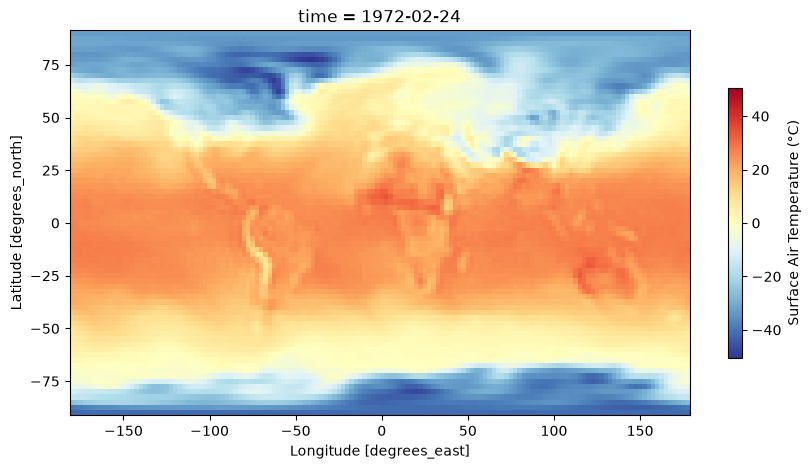

In [98]:
# 1. Open the NetCDF file and convert Kelvin -> Celsius
ds = xr.open_dataset("MappingFiles/compday.0MMqOx1iJi.nc")
air_c = ds["air"].isel(time=0) - 273.15
air_c.attrs["units"] = "°C"

# 2. Shift longitude from 0..357.5 to -180..180 to match EPSG:4326 vectors
air_c = air_c.assign_coords(lon=(((air_c.lon + 180) % 360) - 180)).sortby("lon")

# 3. Load country borders (works in GeoPandas 1.0+ without deprecated gpd.datasets)
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)


# 4. Plot global temperature in Celsius
fig, ax = plt.subplots(figsize=(10, 5))

air_c.plot(
    ax=ax,
    cmap="RdYlBu_r",
    cbar_kwargs={"label": "Surface Air Temperature (°C)", "shrink": 0.7},
)
plt.show()

#### Fifth
- overlay the countries

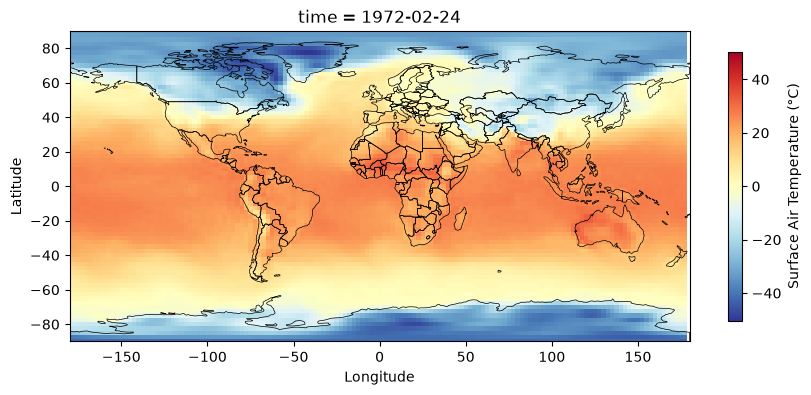

In [99]:
# 1. Open the NetCDF file and convert Kelvin -> Celsius
ds = xr.open_dataset("MappingFiles/compday.0MMqOx1iJi.nc")
air_c = ds["air"].isel(time=0) - 273.15
air_c.attrs["units"] = "°C"

# 2. Shift longitude from 0..357.5 to -180..180 to match EPSG:4326 vectors
air_c = air_c.assign_coords(lon=(((air_c.lon + 180) % 360) - 180)).sortby("lon")

# 3. Load country borders (works in GeoPandas 1.0+ without deprecated gpd.datasets)
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)


# 4. Plot global temperature in Celsius
fig, ax = plt.subplots(figsize=(10, 5))

air_c.plot(
    ax=ax,
    cmap="RdYlBu_r",
    cbar_kwargs={"label": "Surface Air Temperature (°C)", "shrink": 0.7},
)


# 5. Overlay country borders
world.boundary.plot(ax=ax, color="black", linewidth=0.5)

ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

#### Sixth
- Set the temperature range similar to what you see on the news

Text(79.72222222222221, 0.5, 'Latitude')

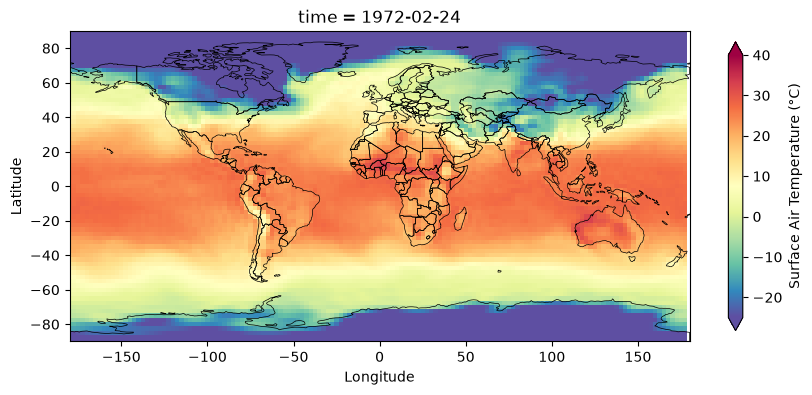

In [100]:
# 1. Open the NetCDF file and convert Kelvin -> Celsius
ds = xr.open_dataset("MappingFiles/compday.0MMqOx1iJi.nc")
air_c = ds["air"].isel(time=0) - 273.15
air_c.attrs["units"] = "°C"

# 2. Shift longitude from 0..357.5 to -180..180 to match EPSG:4326 vectors
air_c = air_c.assign_coords(lon=(((air_c.lon + 180) % 360) - 180)).sortby("lon")

# 3. Load country borders (works in GeoPandas 1.0+ without deprecated gpd.datasets)
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)


# 4. Plot global temperature in Celsius
fig, ax = plt.subplots(figsize=(10, 5))

air_c.plot(
    ax=ax,
    cmap="Spectral_r",  # Or cmocean.cm.thermal with vmin=-50, vmax=40
    vmin=-25,
    vmax=40,
    extend="both",  # Adds pointed end-caps on the colorbar for values outside [-25, 40]
    cbar_kwargs={"label": "Surface Air Temperature (°C)", "shrink": 0.75},
)

# 5. Overlay country borders
world.boundary.plot(ax=ax, color="black", linewidth=0.5)

ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

#### Seventh Zoom in
- Set your bounds
- Set your aspect.
    - Rule of thumb below so you don't have to guess.  Copy and paste

Text(79.72222222222221, 0.5, 'Latitude')

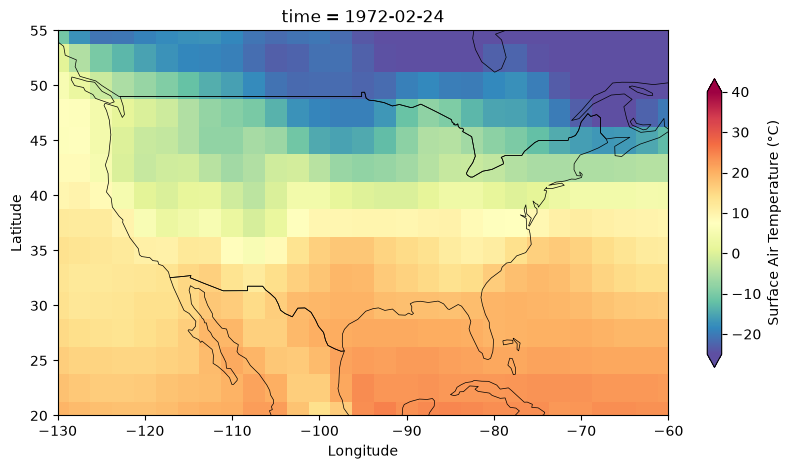

In [101]:
# 1. Open the NetCDF file and convert Kelvin -> Celsius
ds = xr.open_dataset("MappingFiles/compday.0MMqOx1iJi.nc")
air_c = ds["air"].isel(time=0) - 273.15
air_c.attrs["units"] = "°C"

# 2. Shift longitude from 0..357.5 to -180..180 to match EPSG:4326 vectors
air_c = air_c.assign_coords(lon=(((air_c.lon + 180) % 360) - 180)).sortby("lon")

# 3. Load country borders (works in GeoPandas 1.0+ without deprecated gpd.datasets)
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)


# 4. Plot global temperature in Celsius
fig, ax = plt.subplots(figsize=(10, 5))

air_c.plot(
    ax=ax,
    cmap="Spectral_r",  # Or cmocean.cm.thermal with vmin=-50, vmax=40
    vmin=-25,
    vmax=40,
    extend="both",  # Adds pointed end-caps on the colorbar for values outside [-25, 40]
    cbar_kwargs={"label": "Surface Air Temperature (°C)", "shrink": 0.75},
)

# 5. Overlay country borders
world.boundary.plot(ax=ax, color="black", linewidth=0.5)

## Set limits and then aspectm for distoration.  
ax.set_xlim(-130, -60)
ax.set_ylim(20, 55)
mid_lat = (20 + 55) / 2
ax.set_aspect(1 / np.cos(np.deg2rad(mid_lat)))

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

#### Eight Add the states like above

Text(79.72222222222221, 0.5, 'Latitude')

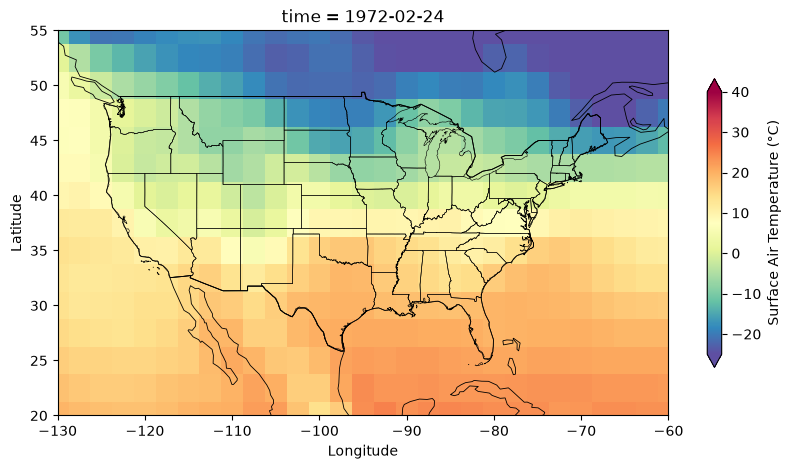

In [102]:
# 1. Open the NetCDF file and convert Kelvin -> Celsius
ds = xr.open_dataset("MappingFiles/compday.0MMqOx1iJi.nc")
air_c = ds["air"].isel(time=0) - 273.15
air_c.attrs["units"] = "°C"

# 2. Shift longitude from 0..357.5 to -180..180 to match EPSG:4326 vectors
air_c = air_c.assign_coords(lon=(((air_c.lon + 180) % 360) - 180)).sortby("lon")

# 3. Load country borders (works in GeoPandas 1.0+ without deprecated gpd.datasets)
url="MappingFiles/110m_cultural/ne_110m_admin_0_countries.shp"
world = gpd.read_file(url)

### States
states = gpd.read_file("MappingFiles/cb_2016_us_state_5m/cb_2016_us_state_5m.shp").to_crs(
    "EPSG:4326")



# 4. Plot global temperature in Celsius
fig, ax = plt.subplots(figsize=(10, 5))

air_c.plot(
    ax=ax,
    cmap="Spectral_r",  # Or cmocean.cm.thermal with vmin=-50, vmax=40
    vmin=-25,
    vmax=40,
    extend="both",  # Adds pointed end-caps on the colorbar for values outside [-25, 40]
    cbar_kwargs={"label": "Surface Air Temperature (°C)", "shrink": 0.75},
)

# 5. Overlay country borders
world.boundary.plot(ax=ax, color="black", linewidth=0.6)
## Overlay states
states.boundary.plot(ax=ax, color="black", linewidth=0.4)


## Set limits and then aspectm for distoration.  
ax.set_xlim(-130, -60)
ax.set_ylim(20, 55)
mid_lat = (20 + 55) / 2
ax.set_aspect(1 / np.cos(np.deg2rad(mid_lat)))

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

<div style="page-break-before: always;"></div>
### Ignore.  For printing to pdf.  

In [126]:
%%html
<style>
@media print {
    body {
        zoom: 0.70; /* Scales everything down to 80% of original size */
    }
}
</style>

In [127]:
import ipynbname
from pypdf import PdfReader, PdfWriter

# Dynamically fetch the current notebook's name (without the .ipynb extension)
filename = ipynbname.name()

# Convert to PDF
!uv run jupyter nbconvert --to webpdf {filename}.ipynb \
    --log-level=CRITICAL \
    --WebPDFExporter.display_header_footer=True \
    --WebPDFExporter.header_template='<span></span>' \
    --WebPDFExporter.footer_template='<div style="font-size: 9pt; font-family: sans-serif; width: 100%; text-align: right; padding-right: 0.5in;"><span class="pageNumber"></span> of <span class="totalPages"></span></div>'

# Strip the last page
reader = PdfReader(f"{filename}.pdf")
writer = PdfWriter()
for page in reader.pages[:-1]:
    writer.add_page(page)
writer.write(f"{filename}.pdf")

(True, <_io.FileIO [closed]>)

In [128]:
from io import BytesIO
import time
import ipynbname
from ipylab import JupyterFrontEnd
from pypdf import PdfReader, PdfWriter
from reportlab.pdfgen import canvas

# 1. Force JupyterLab to save latest changes
app = JupyterFrontEnd()
app.commands.execute("docmanager:save")
time.sleep(1)

# 2. Get current notebook name
filename = ipynbname.name()

# 3. Convert notebook to PDF
!uv run jupyter nbconvert --to webpdf "{filename}.ipynb" --log-level=CRITICAL

# 4. Read PDF and isolate non-setup pages
reader = PdfReader(f"{filename}.pdf")
valid_pages = reader.pages[:-2]  # Strip final page
total_pages = len(valid_pages)


# Helper function to generate page number overlay
def create_footer_overlay(page_num, total, width, height):
  packet = BytesIO()
  c = canvas.Canvas(packet, pagesize=(width, height))
  c.setFont("Helvetica", 9)
  c.setFillColorRGB(0.3, 0.3, 0.3)  # Muted grey text

  # Stamp 0.5 inches (36pt) from bottom-right corner
  c.drawRightString(width - 36, 36, f"Page {page_num} of {total}")
  c.save()
  packet.seek(0)
  return PdfReader(packet).pages[0]


# 5. Stamp numbers and build final PDF
writer = PdfWriter()
for idx, page in enumerate(valid_pages, start=1):
  w = float(page.mediabox.width)
  h = float(page.mediabox.height)

  # Stamp page number onto the current page
  overlay = create_footer_overlay(idx, total_pages, w, h)
  page.merge_page(overlay)
  writer.add_page(page)

writer.write(f"{filename}.pdf")
print(
    f"Successfully generated {filename}.pdf ({total_pages} pages with page numbers)."
)

Successfully generated mapping-2026.pdf (27 pages with page numbers).
